In [101]:
import pprint
import json
from pathlib import Path

def load_json_file(path):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"File not found: {path.resolve()}")

    if not path.read_text(encoding="utf-8").strip():
        raise ValueError(f"JSON file is empty: {path.resolve()}")

    try:
        with path.open("r", encoding="utf-8") as f:
            return json.load(f)
    except json.JSONDecodeError as error:
        raise ValueError(
            f"Invalid JSON in {path.resolve()} "
            f"at line {error.lineno}, column {error.colno}"
        ) from error


drinks_recipes = load_json_file("data/indonesian_drinks.json")
baked_goods_recipes = load_json_file("data/indonesian_baked_goods.json")
western_recipes = load_json_file("data/western_cookies.json")

inspiring_set = drinks_recipes["results"] + baked_goods_recipes["results"] + western_recipes["results"];



# The later cell uses this spelling.
inspring_set = inspiring_set

print(inspring_set)


[{'name': 'Jamu Kunyit Asam (Cook Me Indonesian)', 'family': 'kunyit_asam', 'servings': 8, 'source': 'https://www.cookmeindonesian.com', 'ingredients': [{'name': 'fresh turmeric', 'amount': 300, 'unit': 'g', 'flavour': 'spice', 'type': 'Produce', 'cons': 'SOLID'}, {'name': 'tamarind', 'amount': 50, 'unit': 'g', 'flavour': 'acidity', 'type': 'Ethnic Foods', 'cons': 'SOLID'}, {'name': 'palm sugar', 'amount': 150, 'unit': 'g', 'flavour': 'sweet', 'type': 'Ethnic Foods', 'cons': 'SOLID'}, {'name': 'water', 'amount': 2000, 'unit': 'ml', 'flavour': 'none', 'type': 'Beverages', 'cons': 'LIQUID'}]}, {'name': 'Jamu Kunyit (Cookpad)', 'family': 'kunyit_asam', 'servings': 1, 'source': 'https://cookpad.com/id/resep/26707202', 'ingredients': [{'name': 'turmeric powder', 'amount': 3, 'unit': 'g', 'flavour': 'spice', 'type': 'Spices and Seasonings', 'cons': 'SOLID'}, {'name': 'tamarind', 'amount': 15, 'unit': 'g', 'flavour': 'acidity', 'type': 'Ethnic Foods', 'cons': 'SOLID'}, {'name': 'palm sugar', 

In [102]:
#normalizing data: adding sources & managing tsp/tbsp cases 

def norm_data(recipes):
    for recipe in recipes:
        for i in recipe["ingredients"]:
            i["source"]=recipe["name"]
            if i["unit"] in ["tsp", "tsps"]:
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*5.0

            elif i["unit"] in ["Tbsp", "Tbsps"]:
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*15.0
            elif i["unit"]=="pinch":
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*0.5
            elif i["unit"] in ["stick", "sticks"]:
                i["unit"]="g"
                i["amount"]=i["amount"]*113
            elif i["name"] in ["eggs", "egg", "egg yolk", "egg yolks"]:
                if i["unit"]=="large":
                    i["amount"] = i["amount"] * 55.0
                else:
                    i["amount"] = i["amount"] * 50.0
                i["unit"]="g"
            elif i["unit"] in ["cup", "cups"]:
                if i["cons"] == "LIQUID":
                        i["amount"] = i["amount"] * 240.0
                        i["unit"] = "ml"
                else:
                    i["amount"] = i["amount"] * 130.0
                    i["unit"] = "g"
    return recipes

clist=norm_data(inspring_set)

In [103]:
#creating a list of all indonesian ingredients adding their source

i_ings=[]

for recipe in inspring_set:
    for ing in recipe["ingredients"]:
        if ing["name"] not in ["ice", "water", "sugar", "food colouring"]:
            i_ings.append({**ing, "source": recipe["name"]})

i_names= {ing["name"] for ing in i_ings}

In [104]:
#Initialisation of the population

import random

pop_size=30

population = random.choices(clist, k=pop_size)

In [105]:
#evaluating recipes based on:
#1 how many indonesian drinks they get inspiration from
#2 no more than 12 ingredients (I saw that the average in the original list of Western cookies is 9.74)
# any very important ingredients have no less than 50 g
#no ingredient has less than 5 g
"""
#TODO


- make it create novel recipes
    - the ingredient
- cookies need to tast good
  - sweet
  - sour
  - bitter
  - salty
- correct structure:
    - not too much flour, not too much sugar, not too much fat
        - fat
        - beverages
        - dryness starches
    - not too much liquid, not too much eggs
"""



def evaluate_recipes(recipes):
    for cr in recipes:
        sources=set()
        for i in cr["ingredients"]:
            sources.add(i["source"])

        cr["fitness"]=len(sources)

        if len(cr["ingredients"])>12:
            cr["fitness"]-=3
        
        for i in cr["ingredients"]:
            if i["amount"]<5:
                cr["fitness"]-=2
        
        vii= [ing for ing in cr["ingredients"] if ing["type"] in ["Milk, Eggs, Other Dairy", "Baking"]] #very important ingredients
        for i in vii:
            if i["amount"]<50:
                cr["fitness"]-=2
        
        cr["fitness"]=max(cr["fitness"],0)

In [106]:
#evaluating initial population

evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

In [107]:
#selecting recipes based on their fitness with the Roulette Wheel method used in Simple_PIERRE

def select_recipe(recipes):
  sum_fitness = sum([recipe['fitness'] for recipe in recipes])
  f = random.randint(0, sum_fitness)
  for recipe in recipes: 
    if f < recipe['fitness']:
      return recipe
    f -= recipe['fitness'] 
  return recipes[-1]

In [108]:
def avg_size(cookies):
    sum_i=0
    for c in cookies:
        for i in c["ingredients"]:
            sum_i+=i["amount"]
    return sum_i/len(cookies)

t_size=avg_size(clist)

In [109]:
#from the first recipe we get the general knowledge, from the second the indonesian ingredients

recipe_number = 1

def crossover_recipes(r1, r2):
  global recipe_number
  r1a = [x.copy() for x in r1["ingredients"] if x["type"] in ["Baking", "Milk, Eggs, Other Dairy"]]
  r2b = [y.copy() for y in r2["ingredients"] if y["name"] in i_names]
  r = dict()
  r['name'] = "recipe {}".format(recipe_number)
  recipe_number += 1
  r['ingredients'] = r1a + r2b
  return r

In [110]:
def mutate_recipe(r):
    m = random.randint(0, 4)
    
    #add Indonesian ingredient
    if m==0:
        new_ing=random.choice(i_ings).copy()
        r["ingredients"].append(new_ing)
    
    #reduce a classic ingredient by 10%
    elif m==1:
        cands=[ing for ing in r["ingredients"] if ing["name"] not in i_names]
        if cands:
            sel_ing= random.choice(cands)
            modifier = random.choice([0.9, 1.1])
            sel_ing["amount"]=round(sel_ing["amount"] * modifier, 2)

    #increase the aroma of a typical Indonesian ingredient
    elif m==2:
        cands=[ing for ing in r["ingredients"] if ing["name"] in i_names and ing["type"] in ["Spices and Seasonings", "Canned and Jarred", "Ethnic Foods"]]
        if cands:
            sel_ing= random.choice(cands)
            sel_ing["amount"]=round(sel_ing["amount"] * 1.1, 2)

    #Change classic ingredient with an Indonesian one of the same type
    elif m==3:
        if r["ingredients"]:
            c_cands=[ing for ing in r["ingredients"] if ing["name"] not in i_names]
            if c_cands:
                old_ing = random.choice(c_cands)

                i_cands=[ing for ing in i_ings if ing["cons"] == old_ing["cons"]]
                if not i_cands:
                    i_cands = i_ings
                if i_cands:
                    new_ing = random.choice(i_cands).copy()
                    new_ing["amount"] = old_ing["amount"]

                    new_ing["unit"] = "g" if new_ing["cons"] == "SOLID" else "ml"
                    idx = r["ingredients"].index(old_ing)
                    r["ingredients"][idx] = new_ing
    
    #remove an Indonesian ingredient
    elif m==4:
        cands=[ing for ing in r["ingredients"] if ing["name"] in i_names]
        
        if cands:
            r["ingredients"].remove(random.choice(cands))
    

In [111]:
#normalise recipes

def normalise_recipe(r, inspiring_set):
  unique_ingredients = dict()
  for i in r['ingredients']:
    ing_name=i["name"]
    if ing_name in unique_ingredients:
      unique_ingredients[ing_name]["amount"] += i["amount"]
    else:
        unique_ingredients[ing_name] = i.copy()

  r['ingredients'] = list(unique_ingredients.values())

  sum_amounts = sum([i['amount'] for i in r['ingredients']])
  scale = avg_size(inspiring_set) / sum_amounts
  for i in r['ingredients']:
    i['amount'] = max(1, math.floor(i['amount'] * scale))

In [112]:
def generate_recipes(size, population):
  R = []
  while len(R) < size:
    r1 = select_recipe(population)
    r2 = select_recipe(population)
    r = crossover_recipes(r1, r2)
    mutate_recipe(r)

    # normalise recipe based on western cookie recipe standards
    normalise_recipe(r, western_recipes["results"] )
    R.append(r)
  evaluate_recipes(R)
  return R

In [113]:
def select_population(P, R):
  R = sorted(R, reverse = True, key = lambda r: r['fitness'])
  P = P[0:len(P)//2] + R[0:len(R)//2]
  P = sorted(P, reverse = True, key = lambda r: r['fitness'])
  return P

In [114]:
import math

evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

max_fitnesses = []
min_fitnesses = []
for i in range(1000):
  R = generate_recipes(pop_size, population)
  population = select_population(population, R)
  max_fitnesses.append(population[0]['fitness'])
  min_fitnesses.append(population[-1]['fitness'])

Note: you may need to restart the kernel to use updated packages.


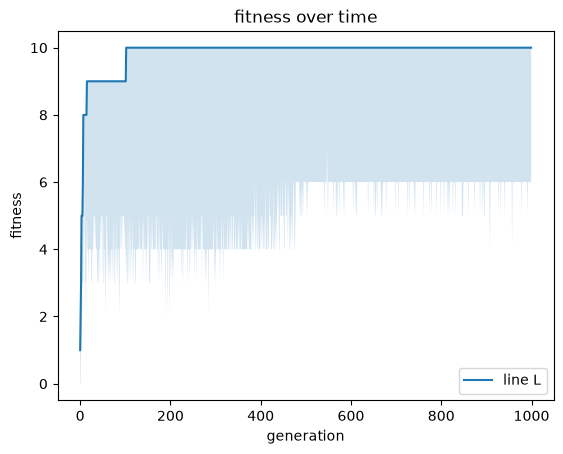

In [115]:
%pip install matplotlib
import matplotlib.pyplot as plt

x  = range(1000)
plt.plot(x, max_fitnesses, label="line L")
plt.fill_between(x, min_fitnesses, max_fitnesses, alpha=0.2)
plt.plot()

plt.xlabel("generation")
plt.ylabel("fitness")
plt.title("fitness over time")
plt.legend()
plt.show()

In [116]:
for i in range (5):
    pprint.PrettyPrinter(indent=2, depth=3).pprint(population[i])


{ 'fitness': 10,
  'ingredients': [ { 'amount': 93,
                     'cons': 'SOLID',
                     'name': 'eggs',
                     'source': 'Chocolate Chip Strawberry Crunch Cookies',
                     'type': 'Milk, Eggs, Other Dairy',
                     'unit': 'g'},
                   { 'amount': 97,
                     'cons': 'SOLID',
                     'flavour': 'none',
                     'name': 'grated coconut',
                     'source': 'Dodol',
                     'type': 'Baking',
                     'unit': 'g'},
                   { 'amount': 74,
                     'cons': 'SOLID',
                     'name': 'sanding sugar',
                     'source': 'Monogram Cookies',
                     'type': 'Baking',
                     'unit': 'g'},
                   { 'amount': 79,
                     'cons': 'SOLID',
                     'name': 'butter',
                     'source': 'Easy Chewy M&M Cookies',
                    